# Simple Workflows using Langgraph

In [1]:
from typing import TypedDict, Optional, NotRequired

## Define the State

In [2]:
class TicketState(TypedDict):
    ticket_id: str
    ticket_content: str
    assigned_queue: NotRequired[Optional[str]]
    processed_by: NotRequired[Optional[str]]
    status: NotRequired[Optional[str]]

In [3]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.'
}

## Define the Graph / Workflow

[ START ] ──> [ CLASSIFY_TICKET ] ──> [ END ]

In [4]:
from langgraph.graph import StateGraph, START, END

In [5]:
def classify_ticket(state: TicketState): 
    ticket_content = state['ticket_content']    
    is_billing = any(keyword in ticket_content for keyword in ['bill', 'refund'])
    assigned_queue = 'billing' if is_billing else 'general'
    return {'assigned_queue': assigned_queue}

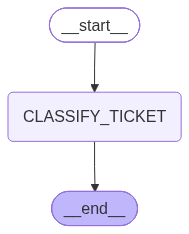

In [6]:
builder = StateGraph(TicketState)

builder.add_node('CLASSIFY_TICKET', classify_ticket)

builder.add_edge(START, 'CLASSIFY_TICKET')
builder.add_edge('CLASSIFY_TICKET', END)

graph = builder.compile()
graph

## Run the Graph / Workflow

In [7]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.'
}

In [8]:
graph.invoke(new_ticket)

{'ticket_id': 'INC125126',
 'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.',
 'assigned_queue': 'billing'}

## A more realistic graph

In [9]:
import random

def classify_ticket(state: TicketState): 
    ticket_content = state['ticket_content']    
    is_billing = any(keyword in ticket_content for keyword in ['bill', 'refund'])
    assigned_queue = 'billing' if is_billing else 'general'
    return {'assigned_queue': assigned_queue}

def billing_queue(state: TicketState):
    processed_by = random.choice(['Adam', 'Bill', 'Catherine'])
    status = random.choice(['REFUND_ISSUED', 'QUESTION_ANSWERED'])
    return {'processed_by': processed_by, 'status': status}

def general_queue(state: TicketState):
    processed_by = random.choice(['David', 'Elizabeth', 'Florence'])
    status = random.choice(['RESOLVED', 'REQUESTED_CLARIFICATION'])
    return {'processed_by': processed_by, 'status': status}

def route_after_classification(state: TicketState):
    return state['assigned_queue'] # 'billing' or 'general'

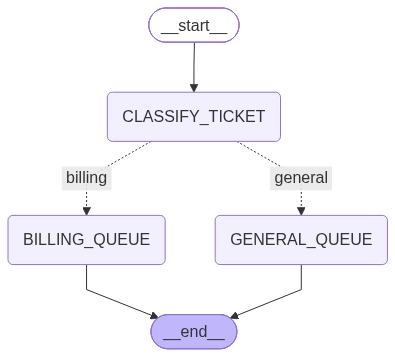

In [10]:
builder = StateGraph(TicketState)

builder.add_node('CLASSIFY_TICKET', classify_ticket)
builder.add_node('BILLING_QUEUE', billing_queue)
builder.add_node('GENERAL_QUEUE', general_queue)

builder.add_edge(START, 'CLASSIFY_TICKET')
builder.add_edge('BILLING_QUEUE', END)
builder.add_edge('GENERAL_QUEUE', END)

builder.add_conditional_edges(
    'CLASSIFY_TICKET', 
    route_after_classification, 
    {
        'billing': 'BILLING_QUEUE',
        'general': 'GENERAL_QUEUE'
    }
)

graph = builder.compile()
graph

In [11]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.'
}

graph.invoke(new_ticket)

{'ticket_id': 'INC125126',
 'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.',
 'assigned_queue': 'billing',
 'processed_by': 'Bill',
 'status': 'QUESTION_ANSWERED'}

In [12]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'My laptop is running very slow. I need help to troubleshoot.'
}

graph.invoke(new_ticket)

{'ticket_id': 'INC125126',
 'ticket_content': 'My laptop is running very slow. I need help to troubleshoot.',
 'assigned_queue': 'general',
 'processed_by': 'Florence',
 'status': 'RESOLVED'}

## Re-Routing between Queues

In [13]:
import random

def classify_ticket(state: TicketState): 
    ticket_content = state['ticket_content']    
    is_billing = any(keyword in ticket_content for keyword in ['bill', 'refund'])
    assigned_queue = 'billing' if is_billing else 'general'
    return {'assigned_queue': assigned_queue}

def billing_queue(state: TicketState):
    processed_by = random.choice(['Adam', 'Bill', 'Catherine'])
    status = random.choice(['REFUND_ISSUED', 'QUESTION_ANSWERED', 'RE-ROUTE'])
    assigned_queue = state['assigned_queue']
    if status  == 'RE-ROUTE':
        assigned_queue = 'general'
    return {'processed_by': processed_by, 'status': status, 'assigned_queue': assigned_queue}

def general_queue(state: TicketState):
    processed_by = random.choice(['David', 'Elizabeth', 'Florence'])
    status = random.choice(['RESOLVED', 'REQUESTED_CLARIFICATION', 'RE-ROUTE'])
    assigned_queue = state['assigned_queue']
    if status  == 'RE-ROUTE':
        assigned_queue = 'billing'
    return {'processed_by': processed_by, 'status': status,  'assigned_queue': assigned_queue}

def route_after_classification(state: TicketState):
    return state['assigned_queue'] # 'billing' or 'general'

def route_after_queue(state: TicketState):
    status = state['status']
    if status == 'RE-ROUTE':
        return state['assigned_queue']
    return 'goto_end'

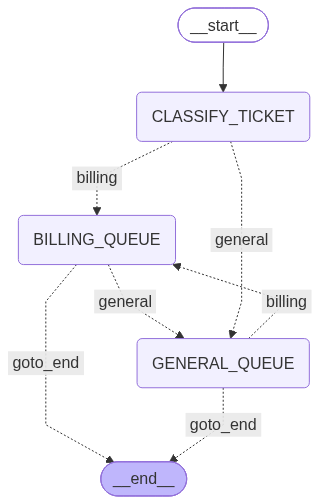

In [14]:
builder = StateGraph(TicketState)

builder.add_node('CLASSIFY_TICKET', classify_ticket)
builder.add_node('BILLING_QUEUE', billing_queue)
builder.add_node('GENERAL_QUEUE', general_queue)

builder.add_edge(START, 'CLASSIFY_TICKET')
# builder.add_edge('BILLING_QUEUE', END)
# builder.add_edge('GENERAL_QUEUE', END)

builder.add_conditional_edges(
    'CLASSIFY_TICKET', 
    route_after_classification, 
    {
        'billing': 'BILLING_QUEUE',
        'general': 'GENERAL_QUEUE'
    }
)

builder.add_conditional_edges(
    'BILLING_QUEUE', 
    route_after_queue, 
    {
        'general': 'GENERAL_QUEUE',
        'goto_end': END,
    }
)

builder.add_conditional_edges(
    'GENERAL_QUEUE', 
    route_after_queue, 
    {
        'billing': 'BILLING_QUEUE',
        'goto_end': END,
    }
)

graph = builder.compile()
graph

In [15]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.'
}

graph.invoke(new_ticket)

{'ticket_id': 'INC125126',
 'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.',
 'assigned_queue': 'billing',
 'processed_by': 'Adam',
 'status': 'REFUND_ISSUED'}

## Adding an audit log

In [16]:
class TicketState(TypedDict):
    ticket_id: str
    ticket_content: str
    assigned_queue: NotRequired[Optional[str]]
    processed_by: NotRequired[Optional[str]]
    status: NotRequired[Optional[str]]
    audit_logs: list[str]

In [17]:
import random

def classify_ticket(state: TicketState): 
    ticket_content = state['ticket_content']    
    is_billing = any(keyword in ticket_content for keyword in ['bill', 'refund'])
    assigned_queue = 'billing' if is_billing else 'general'

    audit_logs = list(state.get('audit_logs') or [])
    audit_logs.append(f'Auto-classified into {assigned_queue} queue')
    
    return {'assigned_queue': assigned_queue, 'audit_logs': audit_logs}

def billing_queue(state: TicketState):
    processed_by = random.choice(['Adam', 'Bill', 'Catherine'])
    status = random.choice(['REFUND_ISSUED', 'QUESTION_ANSWERED', 'RE-ROUTE'])
    
    original_queue = assigned_queue = state['assigned_queue']
    audit_logs = list(state.get('audit_logs') or [])
    
    log_entry = f'{original_queue}: {status} by {processed_by}'    
    if status  == 'RE-ROUTE':
        assigned_queue = 'general'
        log_entry = f'{original_queue}: {status} to {assigned_queue} by {processed_by}'
    audit_logs.append(log_entry)
    
    return {
        'processed_by': processed_by, 
        'status': status, 
        'assigned_queue': assigned_queue,
        'audit_logs': audit_logs,
    }

def general_queue(state: TicketState):
    processed_by = random.choice(['David', 'Elizabeth', 'Florence'])
    status = random.choice(['RESOLVED', 'REQUESTED_CLARIFICATION', 'RE-ROUTE'])
    
    original_queue = assigned_queue = state['assigned_queue']
    audit_logs = list(state.get('audit_logs') or [])
    
    log_entry = f'{original_queue}: {status} by {processed_by}'    
    if status  == 'RE-ROUTE':
        assigned_queue = 'billing'
        log_entry = f'{original_queue}: {status} to {assigned_queue} by {processed_by}'
    audit_logs.append(log_entry)
        
    return {
        'processed_by': processed_by, 
        'status': status, 
        'assigned_queue': assigned_queue,
        'audit_logs': audit_logs,
    }

def route_after_classification(state: TicketState):
    return state['assigned_queue'] # 'billing' or 'general'

def route_after_queue(state: TicketState):
    status = state['status']
    if status == 'RE-ROUTE':
        return state['assigned_queue']
    return 'goto_end'

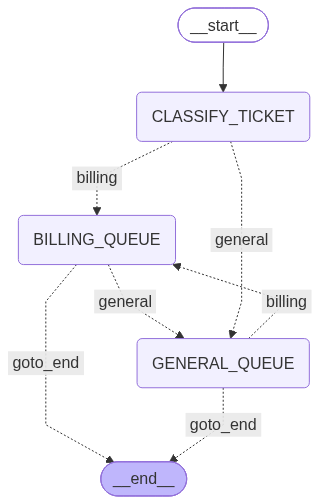

In [18]:
builder = StateGraph(TicketState)

builder.add_node('CLASSIFY_TICKET', classify_ticket)
builder.add_node('BILLING_QUEUE', billing_queue)
builder.add_node('GENERAL_QUEUE', general_queue)

builder.add_edge(START, 'CLASSIFY_TICKET')

builder.add_conditional_edges(
    'CLASSIFY_TICKET', 
    route_after_classification, 
    {
        'billing': 'BILLING_QUEUE',
        'general': 'GENERAL_QUEUE'
    }
)

builder.add_conditional_edges(
    'BILLING_QUEUE', 
    route_after_queue, 
    {
        'general': 'GENERAL_QUEUE',
        'goto_end': END,
    }
)

builder.add_conditional_edges(
    'GENERAL_QUEUE', 
    route_after_queue, 
    {
        'billing': 'BILLING_QUEUE',
        'goto_end': END,
    }
)

graph = builder.compile()
graph

In [19]:
import json

In [20]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'My laptop is runnig slow.',
    'audit_logs': ['Submitted by John Doe']
}

print(json.dumps(graph.invoke(new_ticket), indent=2))

{
  "ticket_id": "INC125126",
  "ticket_content": "My laptop is runnig slow.",
  "assigned_queue": "general",
  "processed_by": "Florence",
  "status": "RESOLVED",
  "audit_logs": [
    "Submitted by John Doe",
    "Auto-classified into general queue",
    "general: RESOLVED by Florence"
  ]
}


## Appending the audit log using reducers

In [21]:
from typing import Annotated
from operator import add

In [22]:
class TicketState(TypedDict):
    ticket_id: str
    ticket_content: str
    assigned_queue: NotRequired[Optional[str]]
    processed_by: NotRequired[Optional[str]]
    status: NotRequired[Optional[str]]
    audit_logs: Annotated[list[str], add]

In [23]:
def classify_ticket(state: TicketState): 
    ticket_content = state['ticket_content']    
    is_billing = any(keyword in ticket_content for keyword in ['bill', 'refund'])
    assigned_queue = 'billing' if is_billing else 'general'

    log_entry = f'Auto-classified into {assigned_queue} queue'
    audit_logs = [log_entry]
    
    return {'assigned_queue': assigned_queue, 'audit_logs': audit_logs}

def billing_queue(state: TicketState):
    processed_by = random.choice(['Adam', 'Bill', 'Catherine'])
    status = random.choice(['REFUND_ISSUED', 'QUESTION_ANSWERED', 'RE-ROUTE'])
    
    original_queue = assigned_queue = state['assigned_queue']
    
    log_entry = f'{original_queue}: {status} by {processed_by}'    
    if status  == 'RE-ROUTE':
        assigned_queue = 'general'
        log_entry = f'{original_queue}: {status} to {assigned_queue} by {processed_by}'
    audit_logs = [log_entry]
    
    return {
        'processed_by': processed_by, 
        'status': status, 
        'assigned_queue': assigned_queue,
        'audit_logs': audit_logs,
    }

def general_queue(state: TicketState):
    processed_by = random.choice(['David', 'Elizabeth', 'Florence'])
    status = random.choice(['RESOLVED', 'REQUESTED_CLARIFICATION', 'RE-ROUTE'])
    
    original_queue = assigned_queue = state['assigned_queue']
    
    log_entry = f'{original_queue}: {status} by {processed_by}'    
    if status  == 'RE-ROUTE':
        assigned_queue = 'billing'
        log_entry = f'{original_queue}: {status} to {assigned_queue} by {processed_by}'
    audit_logs = [log_entry]
        
    return {
        'processed_by': processed_by, 
        'status': status, 
        'assigned_queue': assigned_queue,
        'audit_logs': audit_logs,
    }

def route_after_classification(state: TicketState):
    return state['assigned_queue'] # 'billing' or 'general'

def route_after_queue(state: TicketState):
    status = state['status']
    if status == 'RE-ROUTE':
        return state['assigned_queue']
    return 'goto_end'

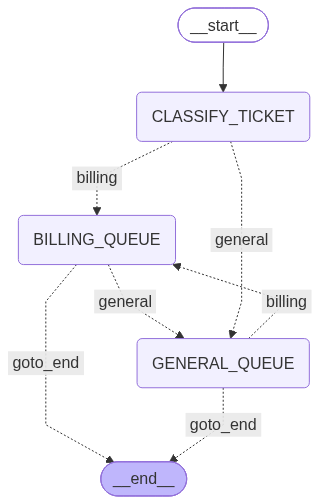

In [24]:
builder = StateGraph(TicketState)

builder.add_node('CLASSIFY_TICKET', classify_ticket)
builder.add_node('BILLING_QUEUE', billing_queue)
builder.add_node('GENERAL_QUEUE', general_queue)

builder.add_edge(START, 'CLASSIFY_TICKET')

builder.add_conditional_edges(
    'CLASSIFY_TICKET', 
    route_after_classification, 
    {
        'billing': 'BILLING_QUEUE',
        'general': 'GENERAL_QUEUE'
    }
)

builder.add_conditional_edges(
    'BILLING_QUEUE', 
    route_after_queue, 
    {
        'general': 'GENERAL_QUEUE',
        'goto_end': END,
    }
)

builder.add_conditional_edges(
    'GENERAL_QUEUE', 
    route_after_queue, 
    {
        'billing': 'BILLING_QUEUE',
        'goto_end': END,
    }
)

graph = builder.compile()
graph

In [25]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'My laptop is runnig slow.',
    'audit_logs': ['Submitted by John Doe']
}

print(json.dumps(graph.invoke(new_ticket), indent=2))

{
  "ticket_id": "INC125126",
  "ticket_content": "My laptop is runnig slow.",
  "assigned_queue": "general",
  "processed_by": "Elizabeth",
  "status": "REQUESTED_CLARIFICATION",
  "audit_logs": [
    "Submitted by John Doe",
    "Auto-classified into general queue",
    "general: REQUESTED_CLARIFICATION by Elizabeth"
  ]
}
